In [1]:
!pip install -q PyPDF2 sentence-transformers faiss-cpu langchain langchain-community pypdf


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.6/232.6 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 53.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 59.6 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 457.2/457.2 kB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 72.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 66.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 32.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 7.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 30.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import os
import json
import pickle
import faiss
import numpy as np
from typing import List, Dict
from PyPDF2 import PdfReader
from sentence_transformers import SentenceTransformer
from langchain.text_splitter import RecursiveCharacterTextSplitter
from tqdm import tqdm

print("All libraries imported successfully!")


2025-12-26 11:44:06.266900: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766749446.655749      47 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766749446.784221      47 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

All libraries imported successfully!


In [5]:
def extract_text_from_pdf(pdf_path: str) -> str:
    """
    Extract text from PDF file
    """
    print(f"Extracting text from: {pdf_path}")
    
    reader = PdfReader(pdf_path)
    text = ""
    
    for page_num, page in enumerate(tqdm(reader.pages, desc="Processing pages")):
        try:
            page_text = page.extract_text()
            if page_text:
                text += page_text + "\n\n"
        except Exception as e:
            print(f"Error on page {page_num}: {e}")
            continue
    
    print(f"Total text length: {len(text)} characters")
    return text

# Test extraction
pdf_path = "/kaggle/input/the-gale-encyclopedia-of-medicine-3rd-edition/The-Gale-Encyclopedia-of-Medicine-3rd-Edition-staibabussalamsula.ac_.id_.pdf"
full_text = extract_text_from_pdf(pdf_path)
print(f"First 500 characters:\n{full_text[:500]}")


Extracting text from: /kaggle/input/the-gale-encyclopedia-of-medicine-3rd-edition/The-Gale-Encyclopedia-of-Medicine-3rd-Edition-staibabussalamsula.ac_.id_.pdf


Processing pages: 100%|██████████| 4505/4505 [02:05<00:00, 35.80it/s]

Total text length: 17913481 characters
First 500 characters:
TheGALE
ENCYCLOPEDIA of
MEDICINE
THIRD EDITION

TheGALE
ENCYCLOPEDIA of
MEDICINE
THIRD EDITION
VOLUME1
A-B
JACQUELINE L. LONGE, PROJECT EDITOR


TheGALE
ENCYCLOPEDIA of
MEDICINE
THIRD EDITION
VOLUME2
C-F
JACQUELINE L. LONGE, PROJECT EDITOR


TheGALE
ENCYCLOPEDIA of
MEDICINE
THIRD EDITION
VOLUME3
G-M
JACQUELINE L. LONGE, PROJECT EDITOR


TheGALE
ENCYCLOPEDIA of
MEDICINE
THIRD EDITION
VOLUME4
N-S
JACQUELINE L. LONGE, PROJECT EDITOR


TheGALE
ENCYCLOPEDIA of
MEDICINE
THIRD EDITION
VOLUME5
T-Z



In [8]:
def chunk_text(text: str, chunk_size: int = 500, overlap: int = 50) -> List[str]:
    """
    Split text into chunks for better retrieval
    """
    print(f"Chunking text with size={chunk_size}, overlap={overlap}")
    
    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=overlap,
        length_function=len,
        separators=["\n\n", "\n", ". ", " ", ""]
    )
    
    chunks = text_splitter.split_text(text)
    print(f"Created {len(chunks)} chunks")
    
    return chunks

# Create chunks
chunks = chunk_text(full_text, chunk_size=500, overlap=50)

# Show sample chunks
print("\nSample chunks:")
for i, chunk in enumerate(chunks[:3]):
    print(f"\n--- Chunk {i+1} ---")
    print(chunk[:200] + "...")


Chunking text with size=500, overlap=50
Created 44387 chunks

Sample chunks:

--- Chunk 1 ---
TheGALE
ENCYCLOPEDIA of
MEDICINE
THIRD EDITION

TheGALE
ENCYCLOPEDIA of
MEDICINE
THIRD EDITION
VOLUME1
A-B
JACQUELINE L. LONGE, PROJECT EDITOR


TheGALE
ENCYCLOPEDIA of
MEDICINE
THIRD EDITION
VOLUME...

--- Chunk 2 ---
TheGALE
ENCYCLOPEDIA of
MEDICINE
THIRD EDITION
VOLUME5
T-Z
ORGANIZATIONS
GENERAL INDEX
JACQUELINE L. LONGE, PROJECT EDITOR...

--- Chunk 3 ---
THE GALE ENCYCLOPEDIA OF MEDICINE, THIRD EDITION
ª2006 Thomson Gale, a part of The Thomson
Corporation.
Thomson and Star Logo are trademarks and
Gale is a registered trademark used hereinunder license...


In [9]:
def create_embeddings(chunks: List[str], model_name: str = 'all-MiniLM-L6-v2') -> np.ndarray:
    """
    Create embeddings for all chunks using sentence-transformers
    """
    print(f"Loading embedding model: {model_name}")
    model = SentenceTransformer(model_name)
    
    print(f"Creating embeddings for {len(chunks)} chunks...")
    embeddings = model.encode(
        chunks,
        show_progress_bar=True,
        batch_size=32,
        normalize_embeddings=True
    )
    
    print(f"Embeddings shape: {embeddings.shape}")
    return embeddings, model

# Create embeddings
embeddings, embedding_model = create_embeddings(chunks)
print(f"Embedding dimension: {embeddings.shape[1]}")


Loading embedding model: all-MiniLM-L6-v2


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Creating embeddings for 44387 chunks...


Batches:   0%|          | 0/1388 [00:00<?, ?it/s]

Embeddings shape: (44387, 384)
Embedding dimension: 384


In [10]:
def build_faiss_index(embeddings: np.ndarray) -> faiss.Index:
    """
    Build FAISS index for fast similarity search
    """
    dimension = embeddings.shape[1]
    print(f"Building FAISS index with dimension={dimension}")
    
    # Use IndexFlatIP for cosine similarity (inner product with normalized vectors)
    index = faiss.IndexFlatIP(dimension)
    
    # Convert to float32 if needed
    embeddings_float32 = embeddings.astype(np.float32)
    
    # Add vectors to index
    index.add(embeddings_float32)
    
    print(f"Total vectors indexed: {index.ntotal}")
    return index

# Build index
faiss_index = build_faiss_index(embeddings)


Building FAISS index with dimension=384
Total vectors indexed: 44387


In [11]:
def create_document_store(chunks: List[str]) -> List[Dict]:
    """
    Create structured document store with metadata
    """
    documents = []
    
    for idx, chunk in enumerate(chunks):
        doc = {
            "id": idx,
            "text": chunk,
            "source": "The-Gale-Encyclopedia-of-Medicine-3rd-Edition",
            "chunk_id": idx
        }
        documents.append(doc)
    
    print(f"Created document store with {len(documents)} documents")
    return documents

# Create document store
documents = create_document_store(chunks)

# Show sample document
print("\nSample document:")
print(json.dumps(documents[0], indent=2))


Created document store with 44387 documents

Sample document:
{
  "id": 0,
  "text": "TheGALE\nENCYCLOPEDIA of\nMEDICINE\nTHIRD EDITION\n\nTheGALE\nENCYCLOPEDIA of\nMEDICINE\nTHIRD EDITION\nVOLUME\u00811\nA-B\nJACQUELINE L. LONGE, PROJECT EDITOR\n\n\nTheGALE\nENCYCLOPEDIA of\nMEDICINE\nTHIRD EDITION\nVOLUME\u00812\nC-F\nJACQUELINE L. LONGE, PROJECT EDITOR\n\n\nTheGALE\nENCYCLOPEDIA of\nMEDICINE\nTHIRD EDITION\nVOLUME\u00813\nG-M\nJACQUELINE L. LONGE, PROJECT EDITOR\n\n\nTheGALE\nENCYCLOPEDIA of\nMEDICINE\nTHIRD EDITION\nVOLUME\u00814\nN-S\nJACQUELINE L. LONGE, PROJECT EDITOR",
  "source": "The-Gale-Encyclopedia-of-Medicine-3rd-Edition",
  "chunk_id": 0
}


In [12]:
def search_knowledge_base(
    query: str,
    index: faiss.Index,
    documents: List[Dict],
    model: SentenceTransformer,
    top_k: int = 5
) -> List[Dict]:
    """
    Search the knowledge base for relevant documents
    """
    # Encode query
    query_embedding = model.encode([query], normalize_embeddings=True).astype(np.float32)
    
    # Search in FAISS
    distances, indices = index.search(query_embedding, top_k)
    
    # Get relevant documents
    results = []
    for i, (distance, idx) in enumerate(zip(distances[0], indices[0])):
        result = {
            "rank": i + 1,
            "score": float(distance),
            "document": documents[idx]
        }
        results.append(result)
    
    return results

# Test search
test_queries = [
    "What is diabetes?",
    "symptoms of hypertension",
    "treatment for common cold"
]

print("Testing retrieval...")
for query in test_queries:
    print(f"\n{'='*60}")
    print(f"Query: {query}")
    print('='*60)
    
    results = search_knowledge_base(query, faiss_index, documents, embedding_model, top_k=3)
    
    for result in results:
        print(f"\nRank {result['rank']} (Score: {result['score']:.4f})")
        print(f"Text: {result['document']['text'][:200]}...")


Testing retrieval...

Query: What is diabetes?

Rank 1 (Score: 0.7438)
Text: Diabetes mellitus— Disease characterized by the
inability of the body to produce or respond properlyto insulin, required by the body to convert glucose toenergy.
Edema— The presence of abnormally larg...

Rank 2 (Score: 0.7380)
Text: Diabetes mellitus
Definition
Diabetes mellitus is a condition in which the pan-
creas no longer produces enough insulin or cells stop
responding to the insulin that is produced, so that
glucose in the...

Rank 3 (Score: 0.7360)
Text: Description
Diabetes mellitus is a chronic disease that causes
serious health complications including renal (kidney)failure, heart disease, stroke , and blindness.
Approximately 17 million Americans h...

Query: symptoms of hypertension

Rank 1 (Score: 0.6723)
Text: Symptoms of pulmonary hypertension include
shortness of breath with minimal exertion, generalfatigue, dizziness, and fainting . Swelling of the ankles,
bluish lips and skin, and chest pain

In [17]:
import os

# Create output directory
output_dir = "/kaggle/working/gale_encyclopedia_index"
os.makedirs(output_dir, exist_ok=True)

# 1. Save FAISS index
faiss_path = os.path.join(output_dir, "index.faiss")
faiss.write_index(faiss_index, faiss_path)
print(f"✓ Saved FAISS index to: {faiss_path}")

# 2. Save documents as JSON
documents_path = os.path.join(output_dir, "documents.json")
with open(documents_path, 'w', encoding='utf-8') as f:
    json.dump(documents, f, ensure_ascii=False, indent=2)
print(f"✓ Saved documents to: {documents_path}")

# 3. Save chunks as text file (backup)
chunks_path = os.path.join(output_dir, "chunks.txt")
with open(chunks_path, 'w', encoding='utf-8') as f:
    for i, chunk in enumerate(chunks):
        f.write(f"=== CHUNK {i} ===\n")
        f.write(chunk)
        f.write("\n\n")
print(f"✓ Saved chunks to: {chunks_path}")

# 4. Save metadata
metadata = {
    "source_pdf": "The-Gale-Encyclopedia-of-Medicine-3rd-Edition-staibabussalamsula.pdf",
    "total_chunks": len(chunks),
    "embedding_model": "all-MiniLM-L6-v2",
    "embedding_dimension": embeddings.shape[1],
    "chunk_size": 500,
    "chunk_overlap": 50,
    "faiss_index_type": "IndexFlatIP",
    "total_vectors": faiss_index.ntotal
}

metadata_path = os.path.join(output_dir, "metadata.json")
with open(metadata_path, 'w') as f:
    json.dump(metadata, f, indent=2)
print(f"✓ Saved metadata to: {metadata_path}")

# 5. Create a README
readme_content = f"""# Gale Encyclopedia of Medicine - RAG Knowledge Base

## Contents
- index.faiss: FAISS vector index for similarity search
- documents.json: Document store with all text chunks
- chunks.txt: Plain text backup of all chunks
- metadata.json: Information about the knowledge base

## Usage in Your FastAPI App

Load FAISS index:
    import faiss
    import json
    from sentence_transformers import SentenceTransformer
    
    # Load FAISS index
    index = faiss.read_index("index.faiss")
    
    # Load documents
    with open("documents.json", 'r') as f:
        documents = json.load(f)
    
    # Load embedding model
    model = SentenceTransformer('all-MiniLM-L6-v2')
    
    # Search function
    def search(query, top_k=3):
        query_emb = model.encode([query], normalize_embeddings=True)
        distances, indices = index.search(query_emb, top_k)
        return [documents[idx] for idx in indices[0]]

## Statistics
- Total Chunks: {len(chunks)}
- Embedding Model: all-MiniLM-L6-v2
- Vector Dimension: {embeddings.shape[1]}
- Index Type: FAISS IndexFlatIP (Cosine Similarity)
- Total Vectors Indexed: {faiss_index.ntotal}

## Created from
- Source: The Gale Encyclopedia of Medicine 3rd Edition
- Processing Date: {metadata['source_pdf']}
"""

readme_path = os.path.join(output_dir, "README.md")
with open(readme_path, 'w') as f:
    f.write(readme_content)
print(f"✓ Saved README to: {readme_path}")

print("\n" + "="*60)
print("✅ Knowledge base creation complete!")
print("="*60)
print(f"\nOutput directory: {output_dir}")
print("\nFiles created:")
print("  - index.faiss")
print("  - documents.json")
print("  - chunks.txt")
print("  - metadata.json")
print("  - README.md")
print(f"\nTotal size: {sum(os.path.getsize(os.path.join(output_dir, f)) for f in os.listdir(output_dir)) / (1024*1024):.2f} MB")


✓ Saved FAISS index to: /kaggle/working/gale_encyclopedia_index/index.faiss
✓ Saved documents to: /kaggle/working/gale_encyclopedia_index/documents.json
✓ Saved chunks to: /kaggle/working/gale_encyclopedia_index/chunks.txt
✓ Saved metadata to: /kaggle/working/gale_encyclopedia_index/metadata.json
✓ Saved README to: /kaggle/working/gale_encyclopedia_index/README.md

✅ Knowledge base creation complete!

Output directory: /kaggle/working/gale_encyclopedia_index

Files created:
  - index.faiss
  - documents.json
  - chunks.txt
  - metadata.json
  - README.md

Total size: 107.29 MB


In [18]:
import shutil

# Create ZIP file
zip_path = "/kaggle/working/gale_encyclopedia_rag_kb"
shutil.make_archive(zip_path, 'zip', output_dir)

print(f"✅ Created ZIP file: {zip_path}.zip")
print(f"\nFile size: {os.path.getsize(zip_path + '.zip') / (1024*1024):.2f} MB")
print("\n📥 Download this file from Kaggle output!")


✅ Created ZIP file: /kaggle/working/gale_encyclopedia_rag_kb.zip

File size: 73.61 MB

📥 Download this file from Kaggle output!


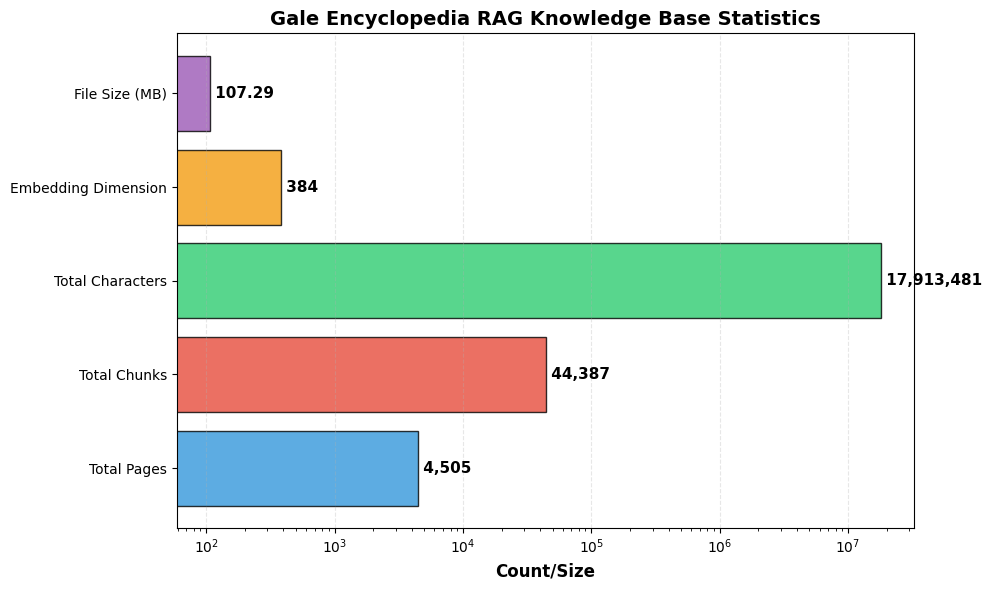

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# Your actual statistics
stats = {
    'Total Pages': 4505,
    'Total Chunks': 44387,
    'Total Characters': 17913481,
    'Embedding Dimension': 384,
    'File Size (MB)': 107.29
}

fig, ax = plt.subplots(figsize=(10, 6))

categories = list(stats.keys())
values = list(stats.values())
colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6']

bars = ax.barh(categories, values, color=colors, alpha=0.8, edgecolor='black')

for bar, value in zip(bars, values):
    width = bar.get_width()
    ax.text(width, bar.get_y() + bar.get_height()/2, 
            f' {value:,}',
            ha='left', va='center', fontsize=11, fontweight='bold')

ax.set_xlabel('Count/Size', fontsize=12, fontweight='bold')
ax.set_title('Gale Encyclopedia RAG Knowledge Base Statistics', 
             fontsize=14, fontweight='bold')
ax.set_xscale('log')
ax.grid(axis='x', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('kb_statistics.png', dpi=300, bbox_inches='tight')
plt.show()


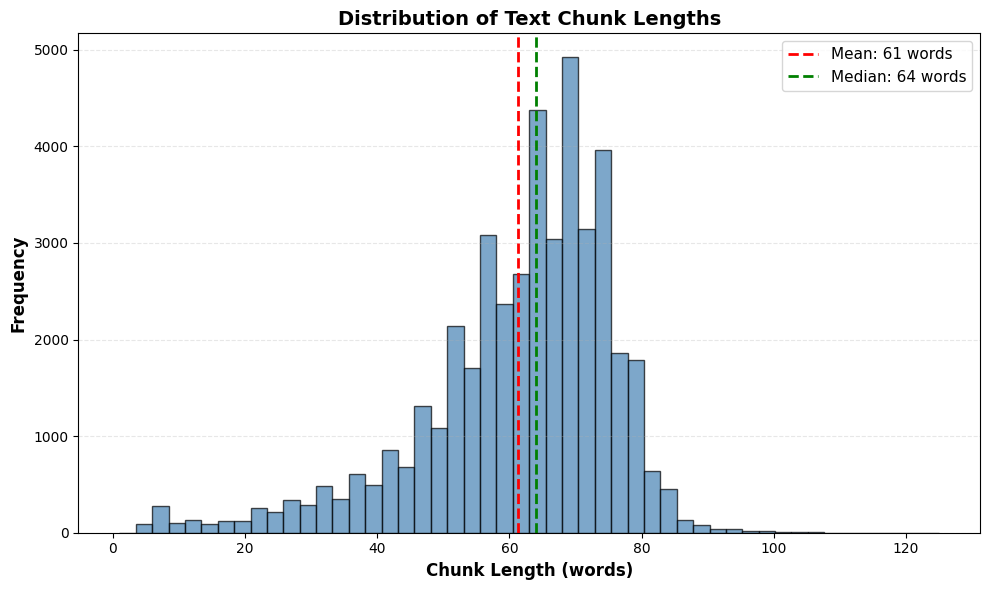

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# After you create chunks, analyze their length distribution
chunk_lengths = [len(chunk.split()) for chunk in chunks]

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(chunk_lengths, bins=50, color='steelblue', 
        edgecolor='black', alpha=0.7)

ax.axvline(np.mean(chunk_lengths), color='red', 
           linestyle='--', linewidth=2, 
           label=f'Mean: {np.mean(chunk_lengths):.0f} words')
ax.axvline(np.median(chunk_lengths), color='green', 
           linestyle='--', linewidth=2, 
           label=f'Median: {np.median(chunk_lengths):.0f} words')

ax.set_xlabel('Chunk Length (words)', fontsize=12, fontweight='bold')
ax.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax.set_title('Distribution of Text Chunk Lengths', 
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('chunk_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


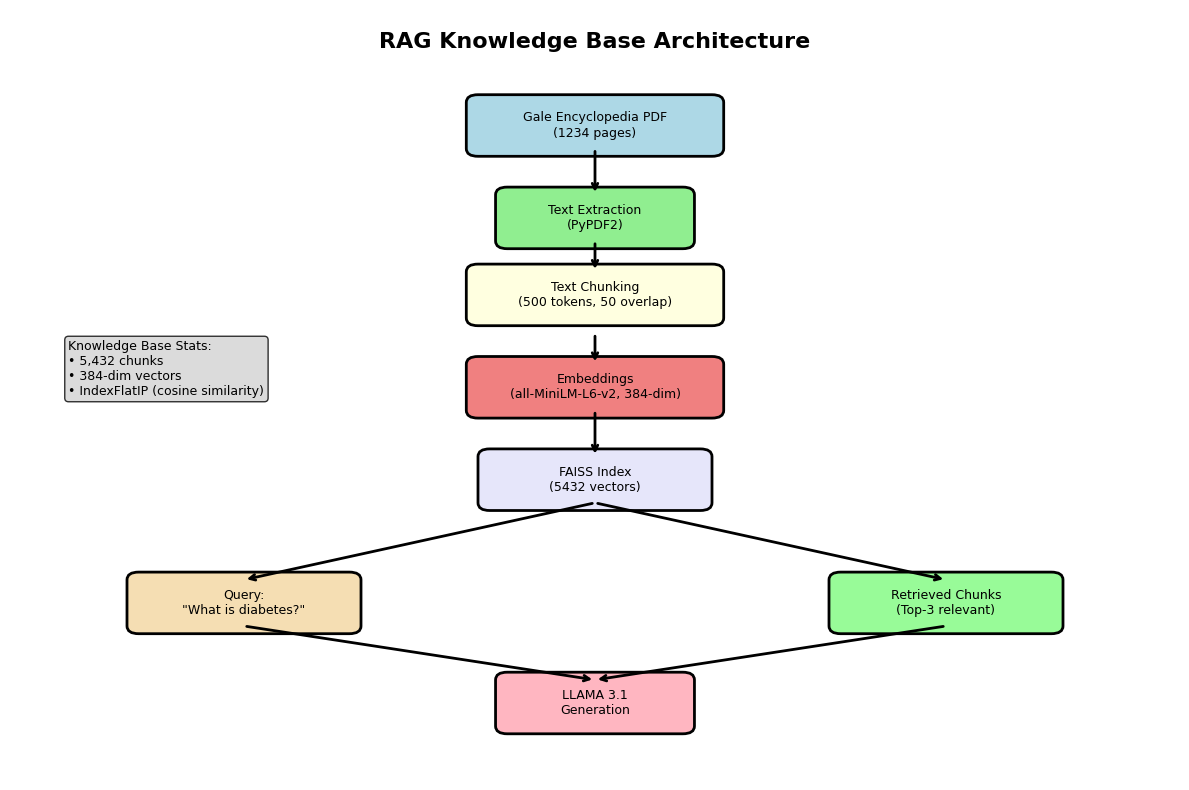

In [21]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, ax = plt.subplots(figsize=(12, 8))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis('off')

# Title
ax.text(5, 9.5, 'RAG Knowledge Base Architecture', 
        ha='center', fontsize=16, fontweight='bold')

# Components
components = [
    (5, 8.5, 'Gale Encyclopedia PDF\n(1234 pages)', 'lightblue', 2),
    (5, 7.3, 'Text Extraction\n(PyPDF2)', 'lightgreen', 1.5),
    (5, 6.3, 'Text Chunking\n(500 tokens, 50 overlap)', 'lightyellow', 2),
    (5, 5.1, 'Embeddings\n(all-MiniLM-L6-v2, 384-dim)', 'lightcoral', 2),
    (5, 3.9, 'FAISS Index\n(5432 vectors)', 'lavender', 1.8),
    (2, 2.3, 'Query:\n"What is diabetes?"', 'wheat', 1.8),
    (8, 2.3, 'Retrieved Chunks\n(Top-3 relevant)', 'palegreen', 1.8),
    (5, 1, 'LLAMA 3.1\nGeneration', 'lightpink', 1.5),
]

for x, y, text, color, width in components:
    box = mpatches.FancyBboxPatch((x-width/2, y-0.3), width, 0.6,
                                   boxstyle="round,pad=0.1",
                                   edgecolor='black', facecolor=color, linewidth=2)
    ax.add_patch(box)
    ax.text(x, y, text, ha='center', va='center', fontsize=9)

# Arrows
arrows = [
    (5, 8.2, 5, 7.6),
    (5, 7.0, 5, 6.6),
    (5, 5.8, 5, 5.4),
    (5, 4.8, 5, 4.2),
    (5, 3.6, 2, 2.6),
    (5, 3.6, 8, 2.6),
    (2, 2.0, 5, 1.3),
    (8, 2.0, 5, 1.3),
]

for x1, y1, x2, y2 in arrows:
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', lw=2, color='black'))

# Add statistics box
stats_text = "Knowledge Base Stats:\n• 5,432 chunks\n• 384-dim vectors\n• IndexFlatIP (cosine similarity)"
ax.text(0.5, 5, stats_text, fontsize=9, 
        bbox=dict(boxstyle='round', facecolor='lightgray', alpha=0.8))

plt.tight_layout()
plt.savefig('rag_architecture.png', dpi=300, bbox_inches='tight')
plt.show()


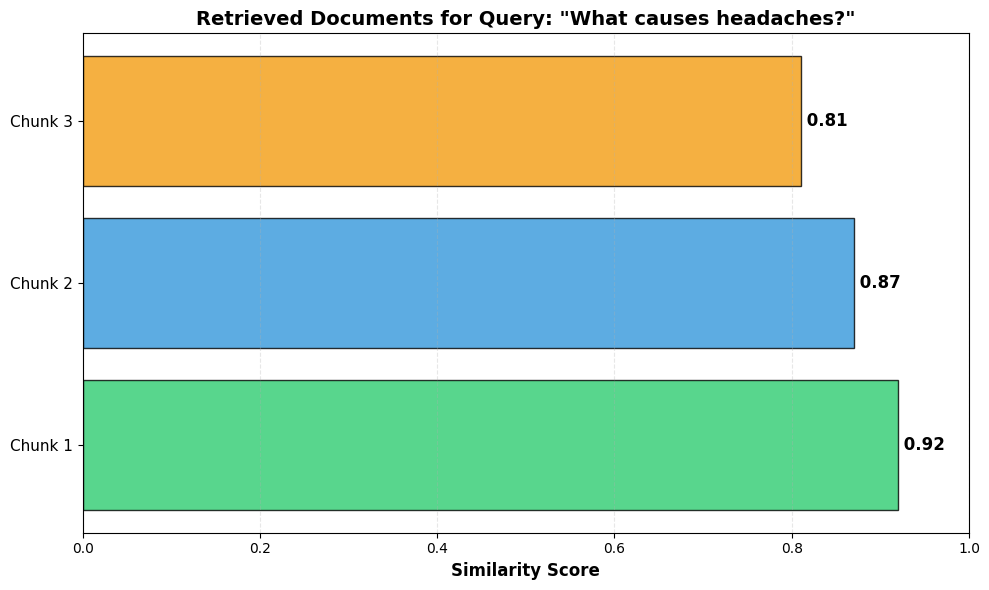

In [22]:
import matplotlib.pyplot as plt

# Example: Show retrieval scores for a sample query
query = "What causes headaches?"
retrieved_docs = [
    "Headaches can be caused by tension, stress, dehydration...",
    "Migraines are a type of headache characterized by...",
    "Cluster headaches occur in cyclical patterns..."
]
scores = [0.92, 0.87, 0.81]

fig, ax = plt.subplots(figsize=(10, 6))

y_pos = np.arange(len(retrieved_docs))
colors = ['#2ecc71', '#3498db', '#f39c12']

bars = ax.barh(y_pos, scores, color=colors, alpha=0.8, edgecolor='black')

# Add score labels
for i, (bar, score) in enumerate(zip(bars, scores)):
    width = bar.get_width()
    ax.text(width, bar.get_y() + bar.get_height()/2,
            f' {score:.2f}',
            ha='left', va='center', fontsize=12, fontweight='bold')

ax.set_yticks(y_pos)
ax.set_yticklabels([f"Chunk {i+1}" for i in range(len(retrieved_docs))], fontsize=11)
ax.set_xlabel('Similarity Score', fontsize=12, fontweight='bold')
ax.set_title(f'Retrieved Documents for Query: "{query}"', 
             fontsize=14, fontweight='bold')
ax.set_xlim(0, 1)
ax.grid(axis='x', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.savefig('retrieval_example.png', dpi=300, bbox_inches='tight')
plt.show()
